# Figure 1. Input dips create On and Off states, and NMDA carries the memory

The rate model (`nmdaint/ratemodel.py`): two memory pools, cued and uncued, with NMDA recurrent excitation and
shared inhibition, driven by a common (attentional) input that briefly dips. The model is read out like the
recordings (`nmdaint/readout.py`): a decoding z score `z = c [r_cued - r_uncued] + eta`, labelled On and Off with the
criteria of Panichello et al. 2024 (`nmdaint/onoff.py`).

Everything here runs in about a minute. Change a parameter and rerun the notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from nmdaint import onoff, ratemodel, readout
from plots import fig1, style

## Parameters

In [2]:
P = ratemodel.params('nmda')            # the fitted model; try ratemodel.params('nmda', tau_N=80) or dip_rate=5
N_TRIALS, SEED = 2112, 1                # simulated trials behind panel b
GAINS = {'high': 2.0, 'mid': 1.0, 'low': 0.5}   # read-out gain relative to the one calibrated to the data
QUIET, DIPS, CUE = 1000, 1500, 75       # example trial (a): ms of delay without dips, then with dips; cue length (ms)
EXAMPLE_TRIAL = 226                     # which of 300 simulated example trials to show (BUGS.md, A1)

## 1. Simulate and read out like the data
The gain `c` is not fitted: it is set so that the model's decoding strength (upper mean of a two-Gaussian mixture
of the delay z) equals the data's for the all-units decoder. The data's statistics come from
`scripts/recordings.py` (`results/recordings/`).

In [3]:
ses, hist = readout.load_data()
out = readout.evaluate(P, ses, n_trials=N_TRIALS, seed=SEED)
r = out['sets']['all']
print(f"memory held in {out['mem']:.1%} of trials; all-units gain c = {r['gain']:.4f} z per Hz")

memory held in 98.4% of trials; all-units gain c = 0.0512 z per Hz


Quick look at one simulated trial: the two pools, their NMDA gating, the common input, and the read-out z with
its On (red) and Off (blue) time points.

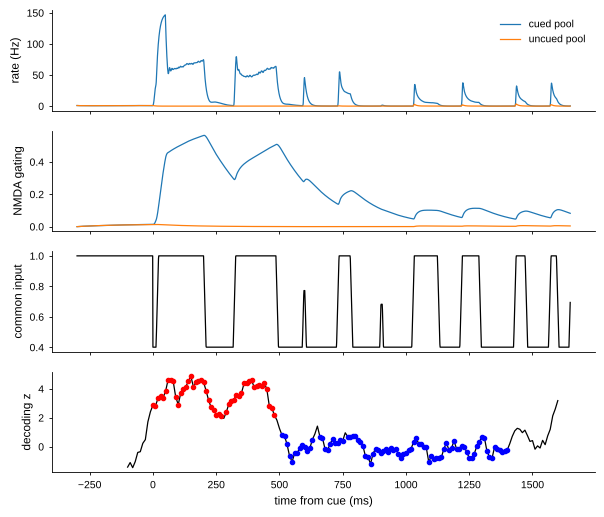

In [4]:
s = out['sim']
j = int(np.argmax((r['state'] == 1).sum(1) * (r['state'] == -1).sum(1)))      # a trial with both states
_, ax = plt.subplots(4, 1, figsize=(7, 6), sharex=True)
ax[0].plot(s['t'], s['rc'][j], label='cued pool'); ax[0].plot(s['t'], s['ru'][j], label='uncued pool')
ax[0].set_ylabel('rate (Hz)'); ax[0].legend()
ax[1].plot(s['t'], s['sc'][j]); ax[1].plot(s['t'], s['su'][j]); ax[1].set_ylabel('NMDA gating')
ax[2].plot(s['t'], s['m'][j], 'k'); ax[2].set_ylabel('common input')
ax[3].plot(out['tz'], r['z'][j], 'k')
for lab, col in ((1, 'r'), (-1, 'b')):
    ax[3].plot(out['tz'][r['state'][j] == lab], r['z'][j][r['state'][j] == lab], '.', color=col)
ax[3].set_ylabel('decoding z'); ax[3].set_xlabel('time from cue (ms)');

## 2. State lengths at three gains (b)
The same simulated trials and the same noise, read out with the gain scaled up and down.

In [5]:
dw, tz = readout.rate_diff(out['sim'])
eta = r['z'] - r['gain'] * dw                                   # the noise of the calibrated read-out
thr = readout.null_threshold(dw.shape, readout.RHO['all'], np.random.default_rng(7))
delay, valid = (tz >= 500) & (tz <= 1400), (tz >= 0) & (tz <= 1400)
lengths = {name: onoff.stats(r['state'] if f == 1 else onoff.label(f * r['gain'] * dw + eta, thr, valid), delay)
           for name, f in GAINS.items()}
for name, s in lengths.items():
    print(f"{name:4s} gain: {s['n_off']:.2f} Off, {s['n_on']:.2f} On states per trial; median Off {s['off_median']:.0f} ms")

high gain: 2.13 Off, 3.08 On states per trial; median Off 90 ms
mid  gain: 3.10 Off, 1.92 On states per trial; median Off 110 ms
low  gain: 3.80 Off, 0.58 On states per trial; median Off 130 ms


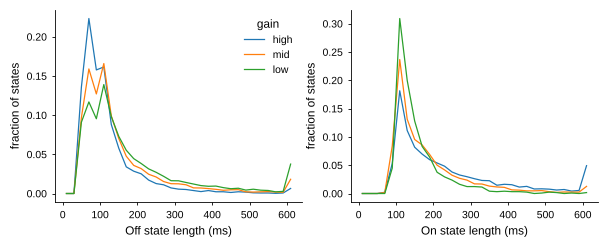

In [6]:
_, ax = plt.subplots(1, 2, figsize=(7, 2.5))
for name, s in lengths.items():
    for a, st in zip(ax, ('off', 'on')):
        a.plot(20 * np.arange(31) + 10, s['h_' + st] / s['h_' + st].sum(), label=name)
for a, st in zip(ax, ('Off', 'On')):
    a.set_xlabel(f'{st} state length (ms)'); a.set_ylabel('fraction of states')
ax[0].legend(title='gain');

## 3. Example trial (a)
A long trial: the common input is constant for the first `QUIET` ms of the delay, then dips as fitted.

In [7]:
p = {**P, 'cue_dur': CUE, 't_delay': QUIET + DIPS - CUE}
sim = ratemodel.simulate(p, 300, seed=12, quiet=QUIET)
rng = np.random.default_rng(11)
dw_e, tz_e = readout.rate_diff(sim, t_from=-250)
eta_e = readout.noise(dw_e.shape, readout.RHO['all'], rng)
state = onoff.label(r['gain'] * dw_e + eta_e, readout.null_threshold(dw_e.shape, readout.RHO['all'], rng), tz_e >= 0)
k = EXAMPLE_TRIAL
example = dict(t=sim['t'], tz=tz_e, dw=dw_e[k], eta=eta_e[k], state=state[k], gain=r['gain'],
               **{v: sim[v][k] for v in ('rc', 'ru', 'sc', 'su', 'm')})
print('memory held at the end of the example trial:', ratemodel.memory_correct(sim)[k])

memory held at the end of the example trial: True


## 4. Play: what do the dips and the NMDA time constant do?
Each variant is simulated (500 trials) and read out with its gain calibrated to the data, as above. Top: when
the memory is lost (mean cued-minus-uncued NMDA gating; the memory counts as held above 0.05). Bottom: On/Off.

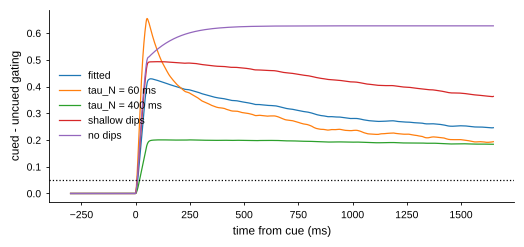

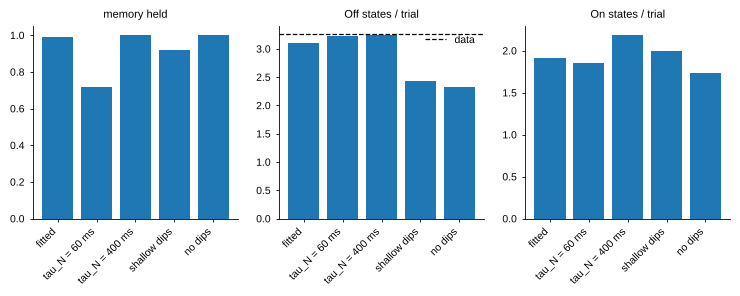

In [8]:
VARIANTS = {'fitted': P, 'tau_N = 60 ms': {**P, 'tau_N': 60}, 'tau_N = 400 ms': {**P, 'tau_N': 400},
            'shallow dips': {**P, 'dip_depth': 0.3}, 'no dips': {**P, 'dip_depth': 0.0}}
play = {name: readout.evaluate(p, ses, n_trials=500, seed=SEED, sets=('all',)) for name, p in VARIANTS.items()}
plt.figure(figsize=(6, 2.5))
for name, o in play.items():
    plt.plot(o['sim']['t'], ratemodel.memory_trace(o['sim']).mean(0), label=name)
plt.axhline(0.05, color='k', ls=':'); plt.xlabel('time from cue (ms)'); plt.ylabel('cued - uncued gating'); plt.legend()
_, ax = plt.subplots(1, 3, figsize=(9, 2.5))
for a, (lab, f) in zip(ax, (('memory held', lambda o: o['mem']), ('Off states / trial', lambda o: o['sets']['all']['n_off']),
                            ('On states / trial', lambda o: o['sets']['all']['n_on']))):
    a.bar(range(len(play)), [f(o) for o in play.values()]); a.set_title(lab)
    a.set_xticks(range(len(play)), list(play), rotation=45, ha='right')
ax[1].axhline(ses['all']['off_per_trial'].mean(), color='k', ls='--', label='data'); ax[1].legend();

## Figure

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


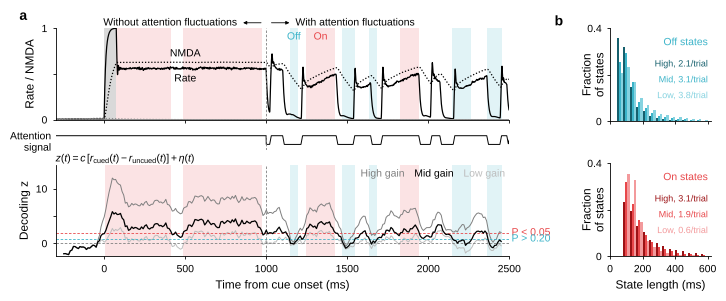

In [9]:
fig = fig1.draw(example, lengths, GAINS, QUIET, CUE, P['r_max'])
style.save(fig, '../figures/fig1.png')